# Notebook 02 — Data Preprocessing and Split Preparation


## 1. Imports


In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


TensorFlow: 2.21.0
NumPy: 1.26.4
Pandas: 3.0.6


## 2. Configure paths and classes


In [2]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD

DATASET_ROOT = PROJECT_ROOT / "data" / "raw" / "dataset_new"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "outputs" / "preprocessing"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["Closed", "Open", "no_yawn", "yawn"]
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SIZE = 0.20

TRAIN_ROOT = DATASET_ROOT / "train"
TEST_ROOT = DATASET_ROOT / "test"

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Processed output:", OUTPUT_DIR)
print("Report output:", REPORT_DIR)

if not TRAIN_ROOT.is_dir() or not TEST_ROOT.is_dir():
    raise FileNotFoundError(
        f"Expected both folders to exist:\n{TRAIN_ROOT}\n{TEST_ROOT}\n"
        "Check the dataset layout confirmed in Notebook 01."
    )

for split_root in [TRAIN_ROOT, TEST_ROOT]:
    missing = [name for name in CLASSES if not (split_root / name).is_dir()]
    if missing:
        raise FileNotFoundError(f"Missing class folders in {split_root}: {missing}")


Project root: D:\driver drowsiness detection final
Dataset root: D:\driver drowsiness detection final\data\raw\dataset_new
Processed output: D:\driver drowsiness detection final\data\processed
Report output: D:\driver drowsiness detection final\outputs\preprocessing


## 3. Build the image manifest


In [3]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def collect_images(split_root: Path, split_name: str) -> pd.DataFrame:
    rows = []
    for class_name in CLASSES:
        class_dir = split_root / class_name
        for path in sorted(class_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS:
                rows.append({
                    "path": str(path.resolve()),
                    "relative_path": str(path.relative_to(PROJECT_ROOT))
                        if path.is_relative_to(PROJECT_ROOT) else str(path),
                    "class_name": class_name,
                    "split_source": split_name
                })
    return pd.DataFrame(rows)

train_source_df = collect_images(TRAIN_ROOT, "train_source")
test_df = collect_images(TEST_ROOT, "test")

if train_source_df.empty or test_df.empty:
    raise ValueError("No images found. Check the dataset folders and supported image extensions.")

print("Original training images:", len(train_source_df))
print("Original test images:", len(test_df))
print("\nTraining source class counts:")
display(train_source_df["class_name"].value_counts().reindex(CLASSES, fill_value=0).rename("count").to_frame())
print("\nTest class counts:")
display(test_df["class_name"].value_counts().reindex(CLASSES, fill_value=0).rename("count").to_frame())


Original training images: 2467
Original test images: 433

Training source class counts:


,count
class_name,
Closed,617
Open,617
no_yawn,616
yawn,617



Test class counts:


,count
class_name,
Closed,109
Open,109
no_yawn,109
yawn,106


## 4. Create a stratified training/validation split


In [4]:
train_df, val_df = train_test_split(
    train_source_df,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=train_source_df["class_name"]
)

train_df = train_df.copy().reset_index(drop=True)
val_df = val_df.copy().reset_index(drop=True)
test_df = test_df.copy().reset_index(drop=True)

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

manifest_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

print("Split sizes:")
display(
    manifest_df.groupby(["split", "class_name"])
    .size().rename("image_count").reset_index()
    .pivot(index="class_name", columns="split", values="image_count")
    .reindex(CLASSES)
)

print("\nTotal rows:", len(manifest_df))


Split sizes:


split,test,train,validation
class_name,,,
Closed,109,494,123
Open,109,493,124
no_yawn,109,493,123
yawn,106,493,124



Total rows: 2900


## 5. Check for exact duplicate leakage across the new splits


In [5]:
import hashlib

def sha256_file(path_string: str) -> str:
    digest = hashlib.sha256()
    with open(path_string, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

manifest_df["sha256"] = manifest_df["path"].map(sha256_file)

overlap_rows = []
for digest, group in manifest_df.groupby("sha256"):
    if group["split"].nunique() > 1:
        overlap_rows.append(group)

if overlap_rows:
    overlap_df = pd.concat(overlap_rows, ignore_index=True)
    overlap_path = REPORT_DIR / "cross_split_exact_duplicates.csv"
    overlap_df.to_csv(overlap_path, index=False)
    print("WARNING: exact duplicates occur across splits. Investigate before training.")
    display(overlap_df[["split", "class_name", "path", "sha256"]])
    print("Saved:", overlap_path)
else:
    overlap_df = pd.DataFrame()
    overlap_path = REPORT_DIR / "cross_split_exact_duplicates.csv"
    overlap_df.to_csv(overlap_path, index=False)
    print("PASS: No exact-content duplicates detected across train/validation/test.")


PASS: No exact-content duplicates detected across train/validation/test.


## 6. Save split manifests and class distribution reports


In [6]:
train_manifest_path = OUTPUT_DIR / "train_manifest.csv"
val_manifest_path = OUTPUT_DIR / "validation_manifest.csv"
test_manifest_path = OUTPUT_DIR / "test_manifest.csv"
combined_manifest_path = OUTPUT_DIR / "all_splits_manifest.csv"

train_df.to_csv(train_manifest_path, index=False)
val_df.to_csv(val_manifest_path, index=False)
test_df.to_csv(test_manifest_path, index=False)
manifest_df.to_csv(combined_manifest_path, index=False)

distribution_df = (
    manifest_df.groupby(["split", "class_name"])
    .size().rename("image_count").reset_index()
)
distribution_df["percentage_within_split"] = distribution_df.groupby("split")["image_count"].transform(
    lambda values: (100 * values / values.sum()).round(2)
)
distribution_path = REPORT_DIR / "split_class_distribution.csv"
distribution_df.to_csv(distribution_path, index=False)

print("Saved manifests:")
for path in [train_manifest_path, val_manifest_path, test_manifest_path, combined_manifest_path, distribution_path]:
    print(" -", path)
display(distribution_df)


Saved manifests:
 - D:\driver drowsiness detection final\data\processed\train_manifest.csv
 - D:\driver drowsiness detection final\data\processed\validation_manifest.csv
 - D:\driver drowsiness detection final\data\processed\test_manifest.csv
 - D:\driver drowsiness detection final\data\processed\all_splits_manifest.csv
 - D:\driver drowsiness detection final\outputs\preprocessing\split_class_distribution.csv


,split,class_name,image_count,percentage_within_split
0,test,Closed,109,25.17
1,test,Open,109,25.17
2,test,no_yawn,109,25.17
3,test,yawn,106,24.48
4,train,Closed,494,25.04
5,train,Open,493,24.99
6,train,no_yawn,493,24.99
7,train,yawn,493,24.99
8,validation,Closed,123,24.90
9,validation,Open,124,25.10


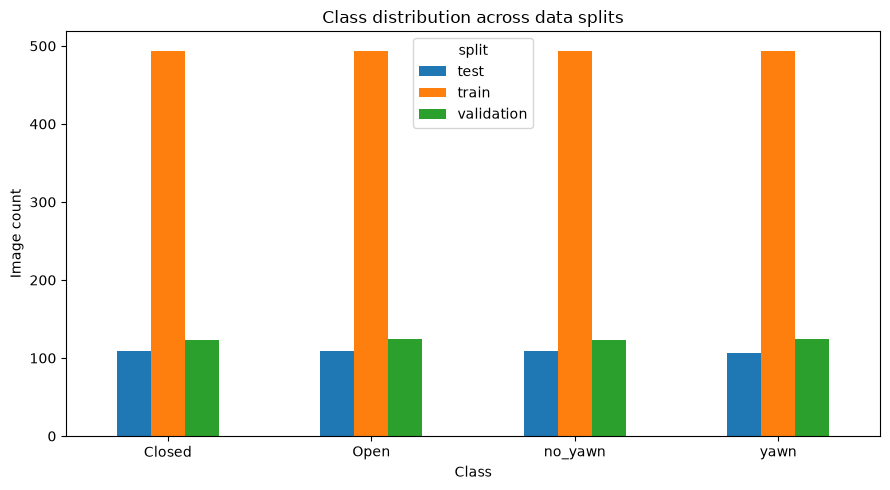

Saved: D:\driver drowsiness detection final\outputs\preprocessing\split_class_distribution.png


In [7]:
pivot = distribution_df.pivot(index="class_name", columns="split", values="image_count").reindex(CLASSES)
ax = pivot.plot(kind="bar", figsize=(9, 5))
ax.set_title("Class distribution across data splits")
ax.set_xlabel("Class")
ax.set_ylabel("Image count")
plt.xticks(rotation=0)
plt.tight_layout()
plot_path = REPORT_DIR / "split_class_distribution.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", plot_path)


## 7. Define preprocessing and augmentation pipelines


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE, method="bilinear")
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomBrightness(0.15, value_range=(0.0, 1.0), seed=SEED),
], name="training_augmentation")

class_to_index = {name: idx for idx, name in enumerate(CLASSES)}
print("Class-to-index mapping:", class_to_index)
print("Image size:", IMAGE_SIZE)


Class-to-index mapping: {'Closed': 0, 'Open': 1, 'no_yawn': 2, 'yawn': 3}
Image size: (224, 224)


## 8. Create TensorFlow datasets and validate preprocessing


In [9]:
def make_tf_dataset(frame: pd.DataFrame, training: bool = False, augment: bool = False):
    paths = frame["path"].astype(str).to_numpy()
    labels = frame["class_name"].map(class_to_index).astype("int32").to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if augment:
        dataset = dataset.map(
            lambda image, label: (augmentation(image, training=True), label),
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return dataset

train_ds = make_tf_dataset(train_df, training=True, augment=True)
train_eval_ds = make_tf_dataset(train_df, training=False, augment=False)
val_ds = make_tf_dataset(val_df, training=False, augment=False)
test_ds = make_tf_dataset(test_df, training=False, augment=False)

print("TensorFlow datasets created.")


TensorFlow datasets created.


In [10]:
# Inspect a training batch.
images, labels = next(iter(train_ds))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Pixel minimum:", float(tf.reduce_min(images).numpy()))
print("Pixel maximum:", float(tf.reduce_max(images).numpy()))
print("Labels in first batch:", labels.numpy()[:10])

assert images.shape[1:] == (224, 224, 3), "Unexpected image shape."
assert float(tf.reduce_min(images).numpy()) >= 0.0, "Pixel values below zero."
assert float(tf.reduce_max(images).numpy()) <= 1.0, "Pixel values above one."

print("PASS: resized image dimensions and [0, 1] pixel range verified.")


Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 1.0
Labels in first batch: [3 2 0 0 3 2 1 1 0 1]
PASS: resized image dimensions and [0, 1] pixel range verified.


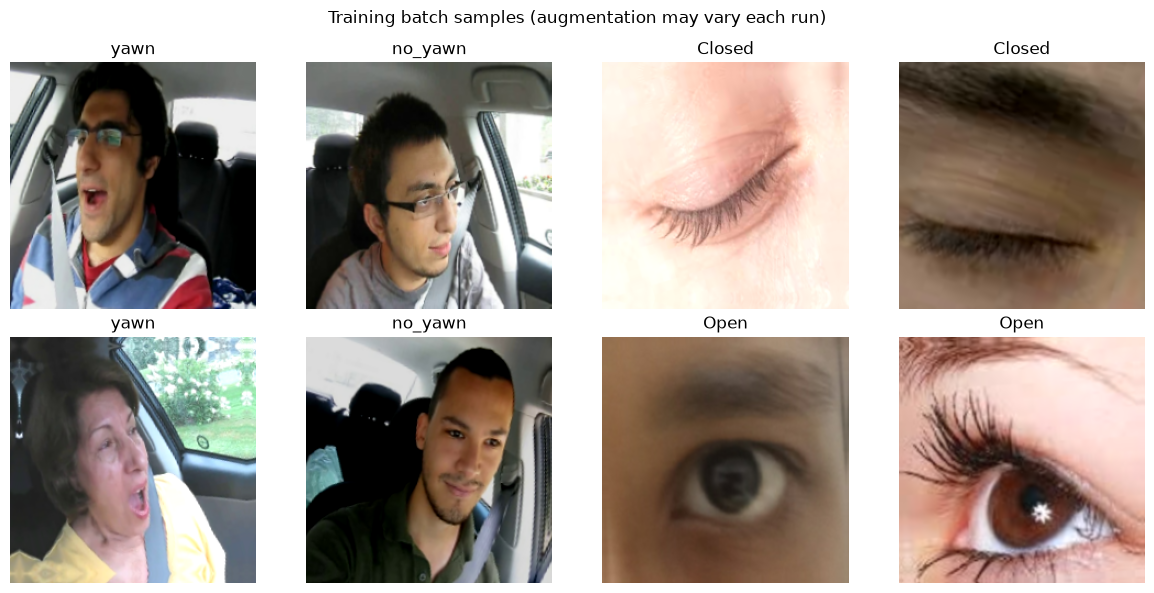

Saved: D:\driver drowsiness detection final\outputs\preprocessing\augmented_training_samples.png


In [11]:
# Show augmented training samples from one batch.
n_show = min(8, images.shape[0])
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < n_show:
        ax.imshow(np.clip(images[i].numpy(), 0, 1))
        ax.set_title(CLASSES[int(labels[i].numpy())])
plt.suptitle("Training batch samples (augmentation may vary each run)")
plt.tight_layout()
aug_plot_path = REPORT_DIR / "augmented_training_samples.png"
plt.savefig(aug_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", aug_plot_path)


## 9. Optional class weights

The classes are close to balanced, so class weights may not be necessary. This cell calculates weights for reference; later training notebooks can decide whether to use them.


In [12]:
y_train = train_df["class_name"].map(class_to_index).to_numpy()
present_classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=present_classes, y=y_train)
class_weights = {int(class_id): float(weight) for class_id, weight in zip(present_classes, weights)}

class_weights_df = pd.DataFrame([
    {"class": CLASSES[class_id], "class_index": class_id, "class_weight": weight}
    for class_id, weight in class_weights.items()
])
display(class_weights_df)
class_weights_path = REPORT_DIR / "class_weights.csv"
class_weights_df.to_csv(class_weights_path, index=False)
print("Saved:", class_weights_path)


,class,class_index,class_weight
0,Closed,0,0.998482
1,Open,1,1.000507
2,no_yawn,2,1.000507
3,yawn,3,1.000507


Saved: D:\driver drowsiness detection final\outputs\preprocessing\class_weights.csv


## 10. Save preprocessing configuration and final checks


In [13]:
config = {
    "dataset_root": str(DATASET_ROOT.resolve()),
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "validation_size_from_original_train": VALIDATION_SIZE,
    "random_seed": SEED,
    "classes": CLASSES,
    "class_to_index": class_to_index,
    "normalization": "float32 pixels divided by 255; range [0, 1]",
    "augmentation": ["horizontal_flip", "rotation", "zoom", "brightness"],
    "augmentation_applied_to": "training only",
    "test_set_usage": "held out for final evaluation only",
    "train_count": len(train_df),
    "validation_count": len(val_df),
    "test_count": len(test_df),
    "exact_cross_split_duplicate_groups": int(
        overlap_df["sha256"].nunique() if not overlap_df.empty else 0
    )
}

config_path = REPORT_DIR / "preprocessing_config.json"
with config_path.open("w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

assert len(set(train_df["path"]) & set(val_df["path"])) == 0
assert len(set(train_df["path"]) & set(test_df["path"])) == 0
assert len(set(val_df["path"]) & set(test_df["path"])) == 0

print("Final split counts:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Config saved:", config_path)

if not overlap_df.empty:
    print("WARNING: Exact duplicates cross splits. Do not train until reviewed.")
else:
    print("PASS: No exact duplicates detected across splits.")

print("Notebook 02 preprocessing setup completed.")


Final split counts:
Train: 1973
Validation: 494
Test: 433
Config saved: D:\driver drowsiness detection final\outputs\preprocessing\preprocessing_config.json
PASS: No exact duplicates detected across splits.
Notebook 02 preprocessing setup completed.
